# Gaussian Mixture Model via Expectation-Maximisation (from scratch)

**Data:** Gapminder (real economic/social data) – GDP per capita and life expectancy of ~140 countries in 2007.
**Goal:** discover groups of countries (by income and health outcomes) without using any labels.

Only `numpy` is used for the algorithm (basic array maths + linear algebra). `pandas`/`matplotlib` are used just for loading data and plotting. **No ML library** (no scikit-learn / scipy) is used.

## The model
$$p(x)=\sum_{k=1}^{K}\pi_k\,\mathcal N(x\mid\mu_k,\Sigma_k),\qquad \sum_k \pi_k=1$$

## EM algorithm
**E-step** – responsibilities:
$$\gamma_{nk}=\frac{\pi_k\,\mathcal N(x_n\mid\mu_k,\Sigma_k)}{\sum_j \pi_j\,\mathcal N(x_n\mid\mu_j,\Sigma_j)}$$

**M-step** – with $N_k=\sum_n\gamma_{nk}$:
$$\pi_k=\frac{N_k}{N},\quad \mu_k=\frac{1}{N_k}\sum_n\gamma_{nk}x_n,\quad \Sigma_k=\frac{1}{N_k}\sum_n\gamma_{nk}(x_n-\mu_k)(x_n-\mu_k)^\top$$

Repeat until the log-likelihood $\sum_n\log\sum_k\pi_k\mathcal N(x_n\mid\mu_k,\Sigma_k)$ stops improving.

## 1. Load and prepare the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)

URL = "https://raw.githubusercontent.com/plotly/datasets/master/gapminderDataFiveYear.csv"
df = pd.read_csv(URL)
df = df[df["year"] == 2007].reset_index(drop=True)
print(df.shape)
df.head()

(142, 6)


,country,year,pop,continent,lifeExp,gdpPercap
0,Afghanistan,2007,31889923.0,Asia,43.828,974.580338
1,Albania,2007,3600523.0,Europe,76.423,5937.029526
2,Algeria,2007,33333216.0,Africa,72.301,6223.367465
3,Angola,2007,12420476.0,Africa,42.731,4797.231267
4,Argentina,2007,40301927.0,Americas,75.320,12779.379640


N = 142  D = 2


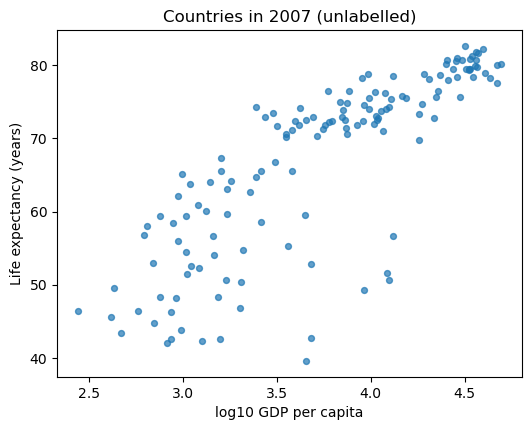

In [2]:
# Features: log10(GDP per capita) and life expectancy
# (GDP is extremely right-skewed, the log makes it much closer to Gaussian)
df["log_gdp"] = np.log10(df["gdpPercap"])
X_raw = df[["log_gdp", "lifeExp"]].to_numpy()

# Standardise so both features are on the same scale
mu_x, sd_x = X_raw.mean(axis=0), X_raw.std(axis=0)
X = (X_raw - mu_x) / sd_x
N, D = X.shape
print("N =", N, " D =", D)

plt.figure(figsize=(6,4.5))
plt.scatter(X_raw[:,0], X_raw[:,1], s=18, alpha=.7)
plt.xlabel("log10 GDP per capita"); plt.ylabel("Life expectancy (years)")
plt.title("Countries in 2007 (unlabelled)"); plt.show()

## 2. EM algorithm from scratch

In [3]:
def logsumexp(a, axis=1):
    """Numerically stable log(sum(exp(a)))."""
    m = np.max(a, axis=axis, keepdims=True)
    return (m + np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True))).squeeze(axis)


def log_gaussian(X, mean, cov):
    """log N(x | mean, cov) for every row of X."""
    D = X.shape[1]
    diff = X - mean
    sign, logdet = np.linalg.slogdet(cov)
    sol = np.linalg.solve(cov, diff.T).T            # cov^{-1} (x-mu)
    maha = np.sum(diff * sol, axis=1)               # Mahalanobis distance^2
    return -0.5 * (D * np.log(2*np.pi) + logdet + maha)


def init_params(X, K, rng):
    """k-means++ style seeding for the means; shared covariance; equal weights."""
    N, D = X.shape
    centres = [X[rng.integers(N)]]
    for _ in range(1, K):
        d2 = np.min([np.sum((X - c)**2, axis=1) for c in centres], axis=0)
        centres.append(X[rng.choice(N, p=d2 / d2.sum())])
    means = np.array(centres)
    covs = np.array([np.cov(X.T) + 1e-6*np.eye(D) for _ in range(K)])
    weights = np.full(K, 1.0 / K)
    return weights, means, covs


def e_step(X, weights, means, covs):
    """Return responsibilities (N,K) and the total log-likelihood."""
    K = len(weights)
    log_p = np.column_stack([np.log(weights[k]) + log_gaussian(X, means[k], covs[k])
                             for k in range(K)])         # log(pi_k N_k)
    log_norm = logsumexp(log_p, axis=1)                  # log p(x_n)
    resp = np.exp(log_p - log_norm[:, None])
    return resp, log_norm.sum()


def m_step(X, resp, reg=1e-6):
    """Update pi, mu, Sigma from responsibilities."""
    N, D = X.shape
    K = resp.shape[1]
    Nk = resp.sum(axis=0)
    weights = Nk / N
    means = (resp.T @ X) / Nk[:, None]
    covs = np.empty((K, D, D))
    for k in range(K):
        diff = X - means[k]
        covs[k] = (resp[:, k, None] * diff).T @ diff / Nk[k] + reg*np.eye(D)  # reg avoids singularity
    return weights, means, covs


def fit_gmm(X, K, max_iter=500, tol=1e-8, seed=0):
    rng = np.random.default_rng(seed)
    weights, means, covs = init_params(X, K, rng)
    ll_hist = []
    for it in range(max_iter):
        resp, ll = e_step(X, weights, means, covs)       # E-step
        weights, means, covs = m_step(X, resp)           # M-step
        ll_hist.append(ll)
        if it > 0 and abs(ll_hist[-1] - ll_hist[-2]) < tol:
            break
    resp, ll = e_step(X, weights, means, covs)
    return dict(weights=weights, means=means, covs=covs, resp=resp,
                ll=ll, ll_hist=ll_hist, n_iter=it+1)


def n_params(K, D):
    return (K - 1) + K*D + K*D*(D+1)//2


def bic(model, N, D):
    K = len(model["weights"])
    return -2*model["ll"] + n_params(K, D)*np.log(N)

## 3. Fit a 3-component GMM
(best of several random restarts, since EM only finds a local maximum)

Log-likelihoods of 10 restarts: [-242.92 -242.92 -238.44 -242.92 -242.92 -242.92 -238.44 -242.92 -238.44
 -242.92]
Best log-likelihood: -238.444  (converged in 32 iterations)


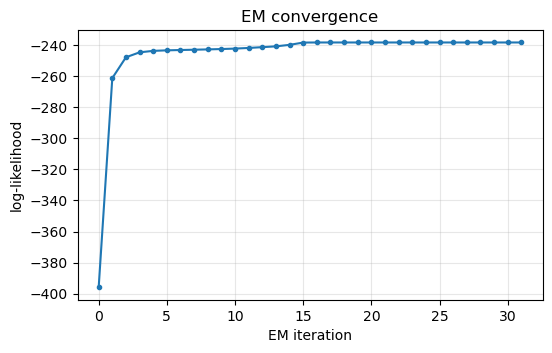

Monotonic increase verified ✔


In [4]:
K = 3
fits = [fit_gmm(X, K, seed=s) for s in range(10)]
best = max(fits, key=lambda m: m["ll"])
print("Log-likelihoods of 10 restarts:", np.round([f["ll"] for f in fits], 2))
print(f"Best log-likelihood: {best['ll']:.3f}  (converged in {best['n_iter']} iterations)")

# Convergence plot – EM log-likelihood must never decrease
plt.figure(figsize=(6,3.5))
plt.plot(best["ll_hist"], marker="o", ms=3)
plt.xlabel("EM iteration"); plt.ylabel("log-likelihood"); plt.title("EM convergence"); plt.grid(alpha=.3)
plt.show()
assert np.all(np.diff(best["ll_hist"]) > -1e-8), "log-likelihood decreased!"
print("Monotonic increase verified ✔")

## 4. Visualise the clusters

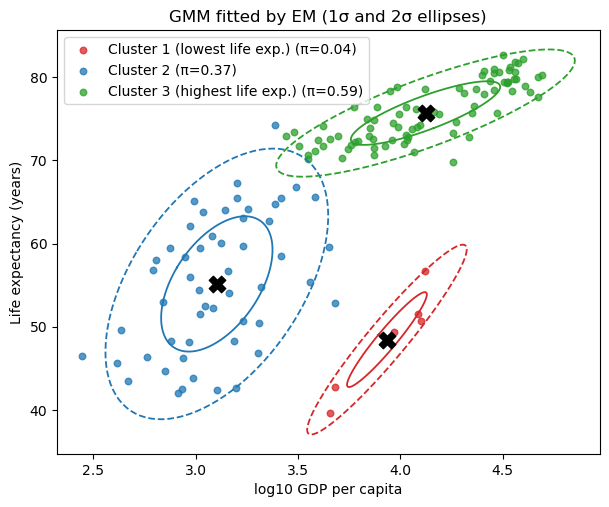

In [5]:
def ellipse_points(mean, cov, n_std=2, n=100):
    vals, vecs = np.linalg.eigh(cov)
    t = np.linspace(0, 2*np.pi, n)
    circle = np.stack([np.cos(t), np.sin(t)])
    return (vecs @ (n_std*np.sqrt(vals)[:, None] * circle)).T + mean

labels = best["resp"].argmax(axis=1)
# order components by mean life expectancy so the labels are stable
order = np.argsort(best["means"][:, 1])
rank = {old: new for new, old in enumerate(order)}
labels = np.array([rank[l] for l in labels])
names = ["Cluster 1 (lowest life exp.)", "Cluster 2", "Cluster 3 (highest life exp.)"]
colors = ["tab:red", "tab:blue", "tab:green"]

plt.figure(figsize=(7,5.5))
for new, old in enumerate(order):
    m = labels == new
    plt.scatter(X_raw[m,0], X_raw[m,1], s=22, c=colors[new], alpha=.75,
                label=f"{names[new]} (π={best['weights'][old]:.2f})")
    for ns, ls in [(1, "-"), (2, "--")]:
        e = ellipse_points(best["means"][old], best["covs"][old], ns) * sd_x + mu_x   # back to original units
        plt.plot(e[:,0], e[:,1], c=colors[new], ls=ls, lw=1.3)
    c = best["means"][old]*sd_x + mu_x
    plt.scatter(*c, marker="X", s=140, c="k", zorder=5)
plt.xlabel("log10 GDP per capita"); plt.ylabel("Life expectancy (years)")
plt.title("GMM fitted by EM (1σ and 2σ ellipses)"); plt.legend(); plt.show()

In [6]:
# Interpret the components in original units
rows = []
for new, old in enumerate(order):
    mean = best["means"][old]*sd_x + mu_x
    rows.append({"cluster": names[new],
                 "weight π": best["weights"][old],
                 "GDP/capita (geo-mean, $)": 10**mean[0],
                 "life expectancy": mean[1],
                 "countries": int((labels == new).sum())})
display(pd.DataFrame(rows).round(2))

df["cluster"] = [names[l] for l in labels]
df["max_resp"] = best["resp"].max(axis=1)
for n in names:
    sub = df[df.cluster == n].sort_values("gdpPercap")
    print(f"\n{n}: {len(sub)} countries, e.g.", ", ".join(sub.country.iloc[::max(1,len(sub)//6)].head(6)))

print("\nMost ambiguous countries (soft assignment):")
display(df.sort_values("max_resp")[["country","continent","gdpPercap","lifeExp","cluster","max_resp"]].head(8).round(3))

,cluster,weight π,"GDP/capita (geo-mean, $)",life expectancy,countries
0,Cluster 1 (lowest life exp.),0.04,8606.94,48.46,6
1,Cluster 2,0.37,1269.46,55.15,53
2,Cluster 3 (highest life exp.),0.59,13284.64,75.68,83



Cluster 1 (lowest life exp.): 6 countries, e.g. Swaziland, Angola, South Africa, Equatorial Guinea, Botswana, Gabon

Cluster 2: 53 countries, e.g. Congo, Dem. Rep., Central African Republic, Guinea, Tanzania, Cote d'Ivoire, Nigeria

Cluster 3 (highest life exp.): 83 countries, e.g. Nicaragua, El Salvador, Cuba, Mexico, Oman, Germany

Most ambiguous countries (soft assignment):


,country,continent,gdpPercap,lifeExp,cluster,max_resp
83,Mongolia,Asia,3095.772,66.803,Cluster 2,0.506
137,Vietnam,Asia,2441.576,74.249,Cluster 2,0.622
69,"Korea, Dem. Rep.",Asia,1593.065,67.297,Cluster 2,0.651
92,Nicaragua,Americas,2749.321,72.899,Cluster 3 (highest life exp.),0.721
138,West Bank and Gaza,Asia,3025.350,73.422,Cluster 3 (highest life exp.),0.772
11,Bolivia,Americas,3822.137,65.554,Cluster 2,0.779
97,Pakistan,Asia,2605.948,65.483,Cluster 2,0.789
108,Sao Tome and Principe,Africa,1598.435,65.528,Cluster 2,0.812


## 5. Choosing the number of components with BIC

K=1: log-lik=-327.53  BIC=679.84
K=2: log-lik=-253.69  BIC=561.89
K=3: log-lik=-238.44  BIC=561.14
K=4: log-lik=-216.62  BIC=547.23
K=5: log-lik=-209.59  BIC=562.89
K=6: log-lik=-199.42  BIC=572.29


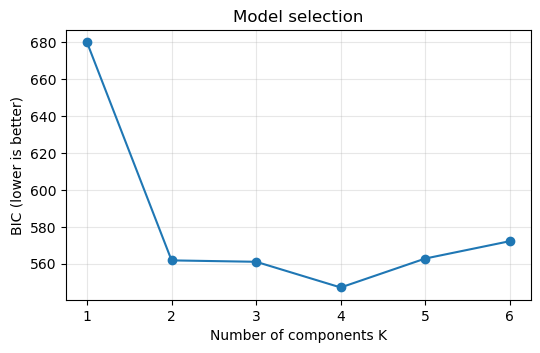

Best K by BIC: 4
(K=3 and K=4 are close; K=3 is easier to interpret, K=4 fits slightly better.)


K=4: log-lik=-216.62  BIC=547.23


K=5: log-lik=-209.59  BIC=562.89


K=6: log-lik=-199.42  BIC=572.29


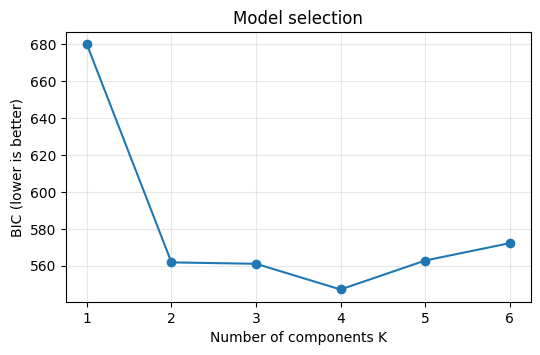

Best K by BIC: 4
(K=3 and K=4 are close; K=3 is easier to interpret, K=4 fits slightly better.)


In [7]:
Ks = range(1, 7)
bics, lls = [], []
for k in Ks:
    m = max((fit_gmm(X, k, seed=s) for s in range(10)), key=lambda f: f["ll"])
    lls.append(m["ll"]); bics.append(bic(m, N, D))
    print(f"K={k}: log-lik={m['ll']:.2f}  BIC={bics[-1]:.2f}")

plt.figure(figsize=(6,3.5))
plt.plot(list(Ks), bics, marker="o")
plt.xlabel("Number of components K"); plt.ylabel("BIC (lower is better)")
plt.title("Model selection"); plt.grid(alpha=.3); plt.show()
print("Best K by BIC:", list(Ks)[int(np.argmin(bics))])
print("(K=3 and K=4 are close; K=3 is easier to interpret, K=4 fits slightly better.)")

## 6. Sanity check on synthetic data
To verify that the implementation is correct, we generate data from known parameters and check that EM recovers them.

In [8]:
rng = np.random.default_rng(42)
true_w = np.array([0.3, 0.7])
true_mu = np.array([[0., 0.], [4., 3.]])
true_cov = np.array([[[1., .5], [.5, 1.]], [[1.5, -.6], [-.6, .8]]])
z = rng.choice(2, size=2000, p=true_w)
Xs = np.array([rng.multivariate_normal(true_mu[k], true_cov[k]) for k in z])

fit = max((fit_gmm(Xs, 2, seed=s) for s in range(5)), key=lambda f: f["ll"])
o = np.argsort(fit["means"][:, 0])
print("weights  true", true_w, " est", fit["weights"][o])
print("means    true\n", true_mu, "\n est\n", fit["means"][o])
print("cov[0]   true\n", true_cov[0], "\n est\n", fit["covs"][o][0])

weights  true [0.3 0.7]  est [0.301 0.699]
means    true
 [[0. 0.]
 [4. 3.]] 
 est
 [[0.032 0.065]
 [3.967 3.035]]
cov[0]   true
 [[1.  0.5]
 [0.5 1. ]] 
 est
 [[1.118 0.633]
 [0.633 1.018]]


## Summary
* Implemented EM for a full-covariance GMM using only NumPy: stable log-sum-exp E-step, closed-form M-step, covariance regularisation, multiple restarts, and a convergence check.
* On 2007 country data, EM separates a poor / low-life-expectancy group, a rich / long-life group, and a small group of southern-African countries with middling GDP but low life expectancy (HIV/AIDS era). Soft assignments (`max_resp`) highlight borderline countries.
* BIC can be used to choose the number of components; the synthetic test confirms parameter recovery.